# 04 Modelado — Espera para una audiencia (Avance 3)
### Taller de Ciencia de Datos · Equipo EMCR

**Pregunta:** cuando un abogado agenda una audiencia de Familia, ¿qué **probabilidad** hay de que la espera sea
**Rápida** (≤ 15 días), **Estándar** (16–30) o con **Demora** (> 30)? Y, como alerta aparte, ¿qué probabilidad hay de
una **espera severa** (> 60 días)?

**Insumo:** `data/processed/audiencias_preparadas_modelo.parquet` (466.178 audiencias, notebook 01).
**Salida:** artefactos en `models/` que lee la página **6.- Modelado y Resultados** de Streamlit.

El código reutilizable está en `src/Modelado/modelo_espera.py`; este notebook lo ejecuta paso a paso y explica cada decisión.
`python src/Modelado/entrenar.py` corre el mismo pipeline sin Jupyter.

## 0. Decisiones fijadas antes de mirar resultados

| Decisión | Valor | Por qué |
|---|---|---|
| Variable objetivo | Tramo en 3 clases + alerta binaria > 60 d | Responde "¿cuánto esperaré?" con probabilidades y marca el riesgo alto |
| Variables de entrada | Tribunal, tipo de procedimiento, tipo de audiencia | Es lo que el abogado sabe al agendar (EDA, secciones 6–9) |
| Validación | **Origen móvil**: elegir prediciendo 2023, reportar prediciendo 2024–2025 | Las filas de una causa no son independientes y el sistema cambia en el tiempo: nunca partición aleatoria |
| Métrica principal | **Log-loss** (y Brier); accuracy y F1 macro como apoyo | Entregamos probabilidades: hay que medir su calidad, no solo el acierto |
| Regla de elección | Menor log-loss en validación; si la diferencia es < 0,002, gana el más simple | Evita elegir mirando la prueba y premia lo explicable |

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
from Modelado import modelo_espera as me

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
COLOR, ROJO = "#2E6F95", "#D1495B"
COLORES_TRAMO = ["#2A9D8F", "#E9B949", "#D1495B"]

df = pd.read_parquet(RAIZ / "data" / "processed" / "audiencias_preparadas_modelo.parquet")
d = me.preparar(df)
print(f"{len(d):,} audiencias · {d['ID_CAUSA_RIT'].nunique():,} causas · años {d['ANIO'].min()}–{d['ANIO'].max()}")

466,178 audiencias · 280,795 causas · años 2015–2025


## 1. Variable objetivo y cambio de régimen

**Por qué:** antes de modelar hay que saber cuánto pesa cada clase y si esa proporción es estable. Si cambia mucho entre
años, un modelo entrenado con el pasado se equivoca de forma sistemática.

,ANIO,n,rapido,estandar,demora,severa
0,2015,44827,41.4%,37.0%,21.5%,1.5%
1,2016,42948,40.0%,35.7%,24.2%,2.4%
2,2017,42572,37.3%,31.5%,31.3%,3.1%
3,2018,43260,34.1%,31.6%,34.2%,4.3%
4,2019,43450,36.1%,27.5%,36.4%,4.8%
5,2020,31080,34.3%,23.5%,42.3%,7.3%
6,2021,42462,25.7%,18.5%,55.8%,16.8%
7,2022,43378,20.4%,15.8%,63.8%,29.2%
8,2023,43380,22.5%,19.4%,58.1%,20.6%
9,2024,44750,29.8%,22.6%,47.7%,20.3%


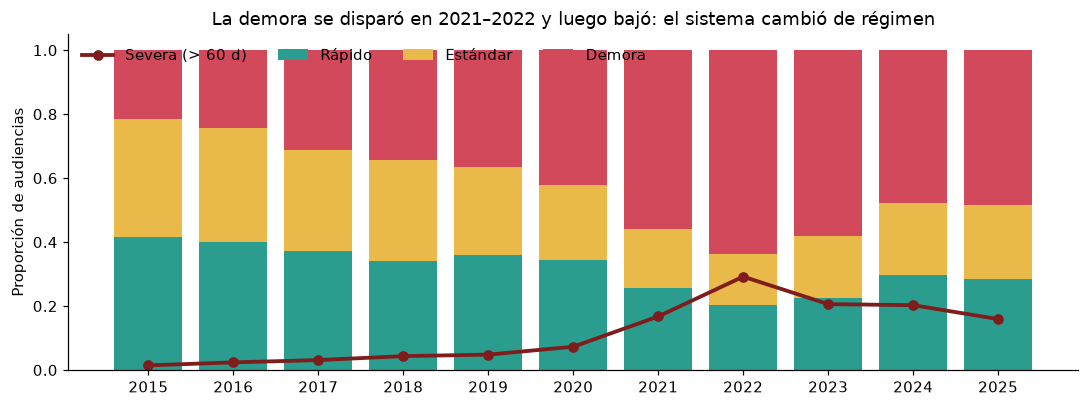

In [2]:
prev = me.prevalencia_por_anio(d)
display(prev.assign(**{c: prev[c].map("{:.1%}".format) for c in ["rapido", "estandar", "demora", "severa"]}))

fig, ax = plt.subplots(figsize=(10, 3.8))
abajo = np.zeros(len(prev))
for col, nombre, c in zip(["rapido", "estandar", "demora"], ["Rápido", "Estándar", "Demora"], COLORES_TRAMO):
    ax.bar(prev["ANIO"], prev[col], bottom=abajo, color=c, label=nombre)
    abajo += prev[col]
ax.plot(prev["ANIO"], prev["severa"], color="#7F1D1D", marker="o", lw=2.5, label="Severa (> 60 d)")
ax.set_ylabel("Proporción de audiencias"); ax.set_xticks(prev["ANIO"])
ax.set_title("La demora se disparó en 2021–2022 y luego bajó: el sistema cambió de régimen")
ax.legend(ncol=4, loc="upper left", frameon=False); plt.tight_layout(); plt.show()

**Lectura:** la Demora pasa de ~22 % (2015) a ~64 % (2022) y baja a ~48 % (2024–2025). La espera severa va de 1,5 % a 29 %.
Consecuencia directa: hay que comparar una ventana de entrenamiento **completa** contra una **reciente**, y revisar la calibración.

## 2. Variables permitidas y excluidas

**Por qué:** un modelo que usa información que el abogado no tiene al agendar se ve excelente en el notebook y no sirve en la práctica (fuga de información).

In [3]:
display(pd.DataFrame({"Variable excluida": list(me.EXCLUIDAS), "Motivo": list(me.EXCLUIDAS.values())}))

# MACRO_MATERIA es una función exacta de TIPO_PROCEDIMIENTO
print("¿Cada procedimiento tiene una sola macro materia?",
      bool((df.groupby("TIPO_PROCEDIMIENTO")["MACRO_MATERIA"].nunique() <= 1).all()))
print("Cardinalidad de las variables usadas:", {v: d[v].nunique() for v in me.VARS})

,Variable excluida,Motivo
0,MACRO_MATERIA,Es una función exacta de TIPO_PROCEDIMIENTO (i...
1,DIAS_TRAMITACION_PREVIA,Se calcula con las mismas fechas que la espera...
2,DIAS_DESPACHO_AGENDAMIENTO,Se calcula con las mismas fechas que la espera...
3,"FECHA_AUDIENCIA (mes, día)",No se conoce al agendar: es justamente lo que ...
4,"DURACION_MINUTOS, FRUSTRADA",Ocurren después de la audiencia.
5,ANO_AUDIENCIA,El sistema cambió de régimen; extrapolar el añ...


¿Cada procedimiento tiene una sola macro materia? True
Cardinalidad de las variables usadas: {'TRIBUNAL': 15, 'TIPO_PROCEDIMIENTO': 12, 'TIPO_AUDIENCIA': 12}


## 3. Esquema de validación: origen móvil

Simulamos estar en una fecha y usamos **solo los años anteriores**:

- **Validación (origen 2023):** se entrena con años ≤ 2022 y se predice 2023. Aquí se **elige** el modelo.
- **Prueba ciega (origen 2024):** se entrena con años ≤ 2023 y se predice 2024–2025. Solo se **reporta**.

Dos **ventanas**: *Completa* (desde 2015) y *Reciente* (últimos 2 años). **Calibrar** significa reservar el último año
antes del origen para ajustar las probabilidades (regresión isotónica) en vez de entrenar con él. Así la variante calibrada
y la no calibrada se comparan en igualdad de condiciones: ninguna ve el periodo que se evalúa.

In [4]:
filas = []
for receta in me.RECETAS:
    for cal in (False, True):
        for etapa, roles in me.esquema(receta, cal).items():
            ent = [a for a, r in roles.items() if r == "Entrenamiento"]
            calib = [a for a, r in roles.items() if r == "Calibración"]
            ev = [a for a, r in roles.items() if r == "Evaluación"]
            filas.append({"Ventana": me.etiqueta_receta(receta), "Calibrado": "Sí" if cal else "No", "Etapa": etapa,
                          "Entrena": f"{min(ent)}–{max(ent)}", "Calibra": calib[0] if calib else "—",
                          "Evalúa": f"{min(ev)}–{max(ev)}" if len(ev) > 1 else ev[0]})
display(pd.DataFrame(filas))

,Ventana,Calibrado,Etapa,Entrena,Calibra,Evalúa
0,Completa (desde 2015),No,Validación (origen 2023),2015–2022,—,2023
1,Completa (desde 2015),No,Prueba (origen 2024),2015–2023,—,2024–2025
2,Completa (desde 2015),Sí,Validación (origen 2023),2015–2021,2022,2023
3,Completa (desde 2015),Sí,Prueba (origen 2024),2015–2022,2023,2024–2025
4,Reciente (últimos 2 años),No,Validación (origen 2023),2021–2022,—,2023
5,Reciente (últimos 2 años),No,Prueba (origen 2024),2022–2023,—,2024–2025
6,Reciente (últimos 2 años),Sí,Validación (origen 2023),2020–2021,2022,2023
7,Reciente (últimos 2 años),Sí,Prueba (origen 2024),2021–2022,2023,2024–2025


## 4. Modelos candidatos y líneas base

| Nivel | Enfoque | Qué es |
|---|---|---|
| Regla | Siempre la clase mayoritaria | Piso mínimo |
| Regla | Moda por tribunal × procedimiento × tipo | Lo que haría alguien con una tabla dinámica |
| Línea base | Distribución global | Probabilidades sin usar ninguna variable |
| Modelo | **Bayesiano jerárquico** | Probabilidad de cada tramo por celda; si la celda tiene pocos casos, se apoya en el nivel superior (Dirichlet–multinomial) |
| Modelo | **Regresión logística multinomial** | Modelo lineal interpretable (efectos aditivos de cada variable) |
| Modelo | **HistGradientBoosting** | Árboles potenciados; capta interacciones. Se promedian 3 semillas |

Cada modelo se evalúa **sin y con calibración**, en las 2 ventanas. Las reglas no entregan probabilidades: no tienen log-loss.

In [5]:
filas_tramo, probs_tramo = [], {}
for receta in me.RECETAS:
    f, p = me.comparar_modelos(d, "Y", receta, log=lambda s: None)
    filas_tramo += f
    probs_tramo[receta] = p
T = pd.DataFrame(filas_tramo)

def tabla(T, conjunto):
    t = T[T["conjunto"] == conjunto].copy()
    t["variante"] = np.where(t["tipo"] == "Modelo", np.where(t["calibrado"], "calibrado", "sin calibrar"), "—")
    cols = ["receta", "modelo", "variante", "accuracy", "f1_macro", "log_loss", "brier"]
    cols += [c for c in ["roc_auc", "pr_auc", "log_loss_ic_inf", "log_loss_ic_sup"] if c in t]
    return t[cols].round(4)

print("VALIDACIÓN 2023 (aquí se elige)")
display(tabla(T, "Validación 2023"))

VALIDACIÓN 2023 (aquí se elige)


,receta,modelo,variante,accuracy,f1_macro,log_loss,brier,log_loss_ic_inf,log_loss_ic_sup
0,Completa (desde 2015),Distribución global (sin variables),—,0.5809,0.2450,1.0479,0.6323,NaN,NaN
1,Completa (desde 2015),Siempre la clase mayoritaria,—,0.5809,0.2450,NaN,NaN,NaN,NaN
2,Completa (desde 2015),Moda por tribunal × procedimiento × tipo,—,0.4998,0.4328,NaN,NaN,NaN,NaN
3,Completa (desde 2015),Bayesiano jerárquico,sin calibrar,0.4997,0.4324,0.9773,0.5926,NaN,NaN
4,Completa (desde 2015),Bayesiano jerárquico,calibrado,0.6836,0.4597,0.8042,0.4603,NaN,NaN
5,Completa (desde 2015),Regresión logística,sin calibrar,0.5239,0.4386,0.9999,0.5933,NaN,NaN
6,Completa (desde 2015),Regresión logística,calibrado,0.6577,0.4306,0.8374,0.4779,NaN,NaN
7,Completa (desde 2015),HistGradientBoosting,sin calibrar,0.5098,0.4372,0.9774,0.5928,NaN,NaN
8,Completa (desde 2015),HistGradientBoosting,calibrado,0.6821,0.4596,0.8025,0.4581,NaN,NaN
18,Reciente (últimos 2 años),Distribución global (sin variables),—,0.5809,0.2450,0.9711,0.5751,NaN,NaN


## 5. Selección del modelo (solo con validación)

In [6]:
el_tramo = me.elegir(filas_tramo)
el_tramo

{'receta_etiqueta': 'Reciente (últimos 2 años)',
 'receta': 'Reciente',
 'modelo': 'Bayesiano jerárquico',
 'calibrado': False,
 'log_loss_validacion': 0.7478683477177663,
 'mejor_log_loss_validacion': 0.7476792863698859}

**Lectura:** el mejor log-loss de validación lo obtienen la ventana **reciente** y los modelos sin calibrar. Gradient Boosting y
el bayesiano jerárquico quedan prácticamente empatados (diferencia menor a 0,002), así que la regla de parsimonia elige el
**bayesiano jerárquico**: rinde igual y se puede explicar celda por celda.

## 6. Resultado en la prueba ciega 2024–2025

Los intervalos de confianza (IC 95 %) del log-loss se obtienen con **bootstrap por causa**: se remuestrean causas completas,
porque las audiencias de una misma causa no son independientes.

In [7]:
display(tabla(T, "Prueba 2024–2025"))
mod = T[(T["conjunto"] == "Prueba 2024–2025") & (T["tipo"] == "Modelo")]
display(mod[["receta", "modelo", "calibrado", "dif_vs_bayes", "dif_ic_inf", "dif_ic_sup"]].dropna().round(4)
        .rename(columns={"dif_vs_bayes": "Δ log-loss vs bayesiano (− = mejor)"}))

,receta,modelo,variante,accuracy,f1_macro,log_loss,brier,log_loss_ic_inf,log_loss_ic_sup
9,Completa (desde 2015),Distribución global (sin variables),—,0.4799,0.2162,1.0602,0.6405,NaN,NaN
10,Completa (desde 2015),Siempre la clase mayoritaria,—,0.4799,0.2162,NaN,NaN,NaN,NaN
11,Completa (desde 2015),Moda por tribunal × procedimiento × tipo,—,0.6105,0.5223,NaN,NaN,NaN,NaN
12,Completa (desde 2015),Bayesiano jerárquico,sin calibrar,0.6118,0.5224,0.8645,0.5158,0.8602,0.8686
13,Completa (desde 2015),Bayesiano jerárquico,calibrado,0.6177,0.4419,0.8671,0.5144,0.8624,0.8720
14,Completa (desde 2015),Regresión logística,sin calibrar,0.5998,0.5111,0.9133,0.5318,0.9090,0.9181
15,Completa (desde 2015),Regresión logística,calibrado,0.6037,0.4267,0.9031,0.5296,0.8983,0.9087
16,Completa (desde 2015),HistGradientBoosting,sin calibrar,0.6168,0.5264,0.8637,0.5151,0.8596,0.8679
17,Completa (desde 2015),HistGradientBoosting,calibrado,0.6203,0.4466,0.8646,0.5127,0.8598,0.8697
27,Reciente (últimos 2 años),Distribución global (sin variables),—,0.4799,0.2162,1.0835,0.6579,NaN,NaN


,receta,modelo,calibrado,Δ log-loss vs bayesiano (− = mejor),dif_ic_inf,dif_ic_sup
14,Completa (desde 2015),Regresión logística,False,0.0489,0.0466,0.0512
15,Completa (desde 2015),Regresión logística,True,0.0360,0.0344,0.0377
16,Completa (desde 2015),HistGradientBoosting,False,-0.0008,-0.0010,-0.0006
17,Completa (desde 2015),HistGradientBoosting,True,-0.0024,-0.0033,-0.0017
32,Reciente (últimos 2 años),Regresión logística,False,0.0397,0.0363,0.0431
33,Reciente (últimos 2 años),Regresión logística,True,0.0076,0.0051,0.0098
34,Reciente (últimos 2 años),HistGradientBoosting,False,-0.0001,-0.0005,0.0004
35,Reciente (últimos 2 años),HistGradientBoosting,True,0.0053,0.0042,0.0062


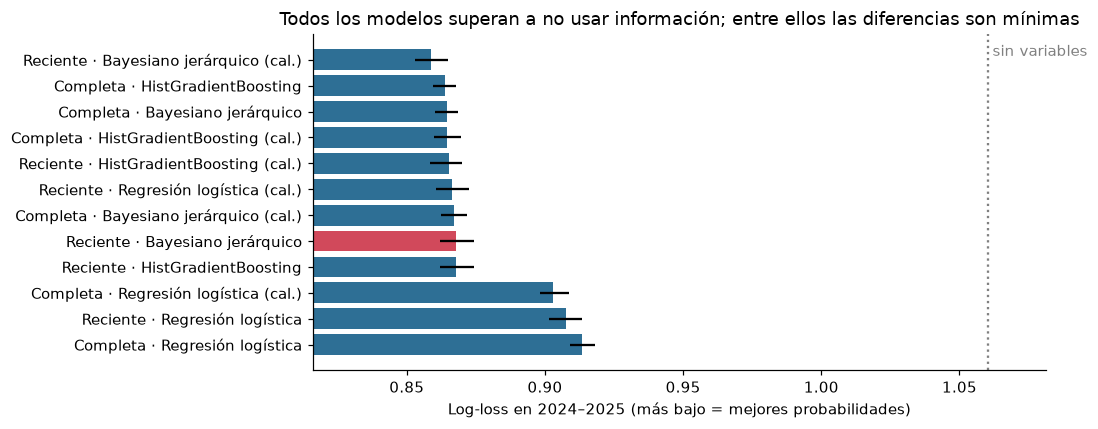

In [8]:
fig, ax = plt.subplots(figsize=(10, 4))
t = mod.assign(etq=mod["receta"].str.split(" ").str[0] + " · " + mod["modelo"] + np.where(mod["calibrado"], " (cal.)", ""))
t = t.sort_values("log_loss")
ax.barh(t["etq"], t["log_loss"], xerr=[t["log_loss"] - t["log_loss_ic_inf"], t["log_loss_ic_sup"] - t["log_loss"]],
        color=[ROJO if (r["modelo"] == el_tramo["modelo"] and r["receta"] == el_tramo["receta_etiqueta"]
                        and r["calibrado"] == el_tramo["calibrado"]) else COLOR for _, r in t.iterrows()])
base = T[(T["conjunto"] == "Prueba 2024–2025") & (T["modelo"].str.startswith("Distribución"))]["log_loss"].min()
ax.axvline(base, ls=":", color="grey"); ax.text(base, -0.6, " sin variables", color="grey", va="top")
ax.invert_yaxis(); ax.set_xlim(t["log_loss"].min() * 0.95, base * 1.02)
ax.set_xlabel("Log-loss en 2024–2025 (más bajo = mejores probabilidades)")
ax.set_title("Todos los modelos superan a no usar información; entre ellos las diferencias son mínimas")
plt.tight_layout(); plt.show()

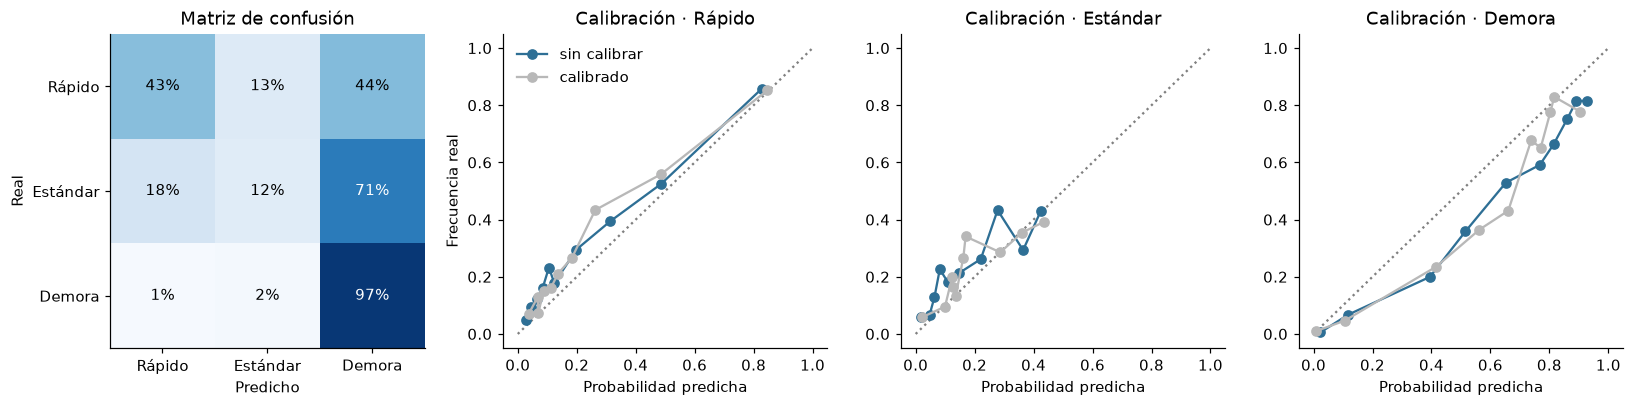

In [9]:
te = me.datos_evaluacion(d, me.ORIGEN_TEST)
P = probs_tramo[el_tramo["receta"]]
P_el = P[(el_tramo["modelo"], el_tramo["calibrado"])]
curvas_tramo = me.curvas_modelo_elegido(te, P_el, P[(el_tramo["modelo"], False)], P[(el_tramo["modelo"], True)], "Y")

fig, ejes = plt.subplots(1, 4, figsize=(15, 3.8))
cm = np.array(curvas_tramo["confusion"])
ejes[0].imshow(cm, cmap="Blues", vmin=0, vmax=1)
nombres = ["Rápido", "Estándar", "Demora"]
for i in range(3):
    for j in range(3):
        ejes[0].text(j, i, f"{cm[i, j]:.0%}", ha="center", va="center", color="white" if cm[i, j] > .5 else "black")
ejes[0].set_xticks(range(3), nombres); ejes[0].set_yticks(range(3), nombres)
ejes[0].set_xlabel("Predicho"); ejes[0].set_ylabel("Real"); ejes[0].set_title("Matriz de confusión")
for ax, clase in zip(ejes[1:], me.CLASES):
    c = curvas_tramo["calibracion"][clase]
    ax.plot([0, 1], [0, 1], ":", color="grey")
    ax.plot(c["sin_calibrar"]["prob_predicha"], c["sin_calibrar"]["frecuencia_real"], "o-", color=COLOR, label="sin calibrar")
    ax.plot(c["calibrado"]["prob_predicha"], c["calibrado"]["frecuencia_real"], "o-", color="#B8B8B8", label="calibrado")
    ax.set_title(f"Calibración · {clase.split(' (')[0]}"); ax.set_xlabel("Probabilidad predicha")
ejes[1].set_ylabel("Frecuencia real"); ejes[1].legend(frameon=False)
plt.tight_layout(); plt.show()

**Lectura:**
- La Demora se detecta casi siempre; el tramo **Estándar** es el más difícil porque queda entre los otros dos.
  Por eso la herramienta muestra **probabilidades** y no solo un tramo.
- Las curvas de calibración siguen la diagonal: cuando el modelo dice 70 %, ocurre cerca del 70 % de las veces.
  Con la ventana reciente, calibrar no agrega nada.

## 7. Alerta de espera severa (> 60 días)

Mismo procedimiento con un objetivo binario. Además del log-loss, se reportan **ROC-AUC** y **PR-AUC** (esta última se
compara con la prevalencia: una alerta al azar tendría PR-AUC igual a la proporción de casos severos).

Elegido: {'receta_etiqueta': 'Reciente (últimos 2 años)', 'receta': 'Reciente', 'modelo': 'Bayesiano jerárquico', 'calibrado': False, 'log_loss_validacion': 0.35981942956008156, 'mejor_log_loss_validacion': 0.3584464289410869}


,receta,modelo,variante,accuracy,f1_macro,log_loss,brier,roc_auc,pr_auc,log_loss_ic_inf,log_loss_ic_sup
9,Completa (desde 2015),Distribución global (sin variables),—,0.8188,0.4502,0.5030,0.1549,0.5000,0.1812,NaN,NaN
10,Completa (desde 2015),Siempre la clase mayoritaria,—,0.8188,0.4502,NaN,NaN,NaN,NaN,NaN,NaN
11,Completa (desde 2015),Moda por tribunal × procedimiento × tipo,—,0.8193,0.4954,NaN,NaN,NaN,NaN,NaN,NaN
12,Completa (desde 2015),Bayesiano jerárquico,sin calibrar,0.8193,0.4953,0.4083,0.1313,0.8068,0.4623,0.4030,0.4133
13,Completa (desde 2015),Bayesiano jerárquico,calibrado,0.8327,0.6270,0.3933,0.1300,0.7826,0.3928,0.3898,0.3972
14,Completa (desde 2015),Regresión logística,sin calibrar,0.8204,0.4627,0.4293,0.1362,0.7834,0.4312,0.4239,0.4345
15,Completa (desde 2015),Regresión logística,calibrado,0.8244,0.6119,0.4107,0.1324,0.7543,0.3871,0.4069,0.4149
16,Completa (desde 2015),HistGradientBoosting,sin calibrar,0.8193,0.4953,0.4080,0.1313,0.8079,0.4648,0.4028,0.4131
17,Completa (desde 2015),HistGradientBoosting,calibrado,0.8324,0.6137,0.3946,0.1307,0.7772,0.3936,0.3888,0.3963
27,Reciente (últimos 2 años),Distribución global (sin variables),—,0.8188,0.4502,0.4864,0.1530,0.5000,0.1812,NaN,NaN


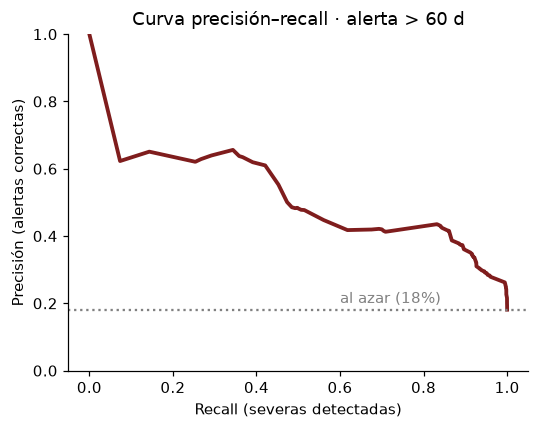

In [10]:
filas_sev, probs_sev = [], {}
for receta in me.RECETAS:
    f, p = me.comparar_modelos(d, "SEVERA", receta, log=lambda s: None)
    filas_sev += f
    probs_sev[receta] = p
S = pd.DataFrame(filas_sev)
el_sev = me.elegir(filas_sev)
print("Elegido:", el_sev)
display(tabla(S, "Prueba 2024–2025"))
P = probs_sev[el_sev["receta"]]
curvas_sev = me.curvas_modelo_elegido(te, P[(el_sev["modelo"], el_sev["calibrado"])], P[(el_sev["modelo"], False)],
                                      P[(el_sev["modelo"], True)], "SEVERA")
fig, ax = plt.subplots(figsize=(5, 4))
ax.plot(curvas_sev["pr"]["recall"], curvas_sev["pr"]["precision"], color="#7F1D1D", lw=2.5)
ax.axhline(curvas_sev["prevalencia"], ls=":", color="grey")
ax.text(0.6, curvas_sev["prevalencia"] + 0.02, f"al azar ({curvas_sev['prevalencia']:.0%})", color="grey")
ax.set_xlabel("Recall (severas detectadas)"); ax.set_ylabel("Precisión (alertas correctas)")
ax.set_title("Curva precisión–recall · alerta > 60 d"); ax.set_ylim(0, 1); plt.tight_layout(); plt.show()

## 8. Ablación: ¿más variables ayudan?

**Por qué:** demostrar que el modelo no queda corto por falta de variables disponibles. Se agrega al modelo base (HistGradientBoosting,
ventana elegida, sin calibrar): (B) modalidad y mes/día de **programación**; (C) la **congestión del tribunal**, es decir, la espera
promedio de sus audiencias ya realizadas en los 90 días previos a la programación (información disponible al agendar).

In [11]:
ab = pd.DataFrame(me.ablacion(d, el_tramo["receta"], log=lambda s: None))
display(ab.pivot(index="variables", columns="conjunto", values="log_loss").round(4))

conjunto,Prueba 2024–2025,Validación 2023
variables,,
A · Tribunal + procedimiento + tipo,0.8677,0.7480
B · A + modalidad + mes y día de programación,0.9320,0.8368
C · A + congestión del tribunal (90 días previos),1.0203,0.9125


**Lectura:** ninguna variable adicional mejora; al contrario, empeoran la prueba. La congestión reciente cambia mucho entre
periodos y el modelo la extrapola mal. Se mantienen las 3 variables base.

## 9. Volatilidad por tribunal

**Por qué:** explica por qué conviene entrenar con los datos más recientes. Algunos tribunales cambian bruscamente de un año a otro.

In [12]:
s = d[(d["TIPO_PROCEDIMIENTO"] == "CONTENCIOSA") & (d["TIPO_AUDIENCIA"] == "AUDIENCIA PREPARATORIA") & (d["ANIO"] >= 2021)]
vol = s.groupby(["TRIBUNAL", "ANIO"])["Y"].apply(lambda y: (y == 2).mean()).unstack()
vol.index = vol.index.str.replace("JUZGADO DE FAMILIA DE ", "JF ").str.replace("JUZGADO DE LETRAS Y GARANTIA DE ", "JLG ")
vol["rango"] = vol.max(1) - vol.min(1)
display(vol.sort_values("rango", ascending=False).style.format("{:.0%}").background_gradient(cmap="YlOrRd", axis=None,
        subset=[c for c in vol.columns if c != "rango"]))

ANIO,2021,2022,2023,2024,2025,rango
TRIBUNAL,,,,,,
JF VILLA ALEMANA,84%,93%,9%,74%,88%,83%
JLG PUTAENDO,10%,84%,68%,68%,75%,74%
JLG PETORCA,2%,71%,34%,56%,74%,72%
JF LOS ANDES,90%,92%,88%,26%,51%,66%
JLG ISLA DE PASCUA,24%,63%,31%,17%,20%,46%
JF QUILLOTA,81%,95%,84%,57%,90%,38%
JF LIMACHE,56%,51%,47%,24%,58%,34%
JF QUILPUE,56%,72%,65%,49%,40%,33%
JF VALPARAISO,60%,84%,82%,86%,84%,26%


**Lectura:** en preparatorias contenciosas, Villa Alemana pasa de 9 % de audiencias con demora en 2023 a 88 % en 2025.
Un modelo estático quedaría obsoleto en meses: el modelo final se reentrena con los dos últimos años.

## 10. Modelo final y comparador de tribunales

La variante elegida se reentrena con **todos los datos disponibles** (origen 2026: ventana reciente 2024–2025). Con ella se
calculan las probabilidades para cada tribunal × procedimiento × tipo, junto con la espera real de 2024–2025 y un **IC 95 % por
bootstrap** de la mediana. Si los intervalos de dos tribunales se cruzan, no hay diferencia clara entre ellos.

> **Uso responsable:** el comparador sirve para elegir **entre tribunales legalmente competentes** (por ejemplo, alimentos,
> donde la ley permite elegir domicilio). Cambiar o inventar un domicilio no es legítimo.

In [13]:
m_tramo, info_t = me.entrenar_final(d, el_tramo, "Y")
m_sev, info_s = me.entrenar_final(d, el_sev, "SEVERA")
print("Tramo:", info_t, "· Alerta:", info_s)
grilla = me.grilla_tribunales(d, m_tramo, m_sev)

ej = grilla[(grilla["TIPO_PROCEDIMIENTO"] == "CONTENCIOSA") & (grilla["TIPO_AUDIENCIA"] == "AUDIENCIA PREPARATORIA") & (grilla["n"] >= 30)]
ej = ej.sort_values("mediana")
ej_vista = ej[["TRIBUNAL", "n", "mediana", "mediana_ic_inf", "mediana_ic_sup", "p_rapido", "p_demora", "p_severa"]].copy()
ej_vista["TRIBUNAL"] = ej_vista["TRIBUNAL"].str.replace("JUZGADO DE FAMILIA DE ", "JF ").str.replace("JUZGADO DE LETRAS Y GARANTIA DE ", "JLG ")
display(ej_vista.style.format({"mediana": "{:.0f}", "mediana_ic_inf": "{:.0f}", "mediana_ic_sup": "{:.0f}",
                               "p_rapido": "{:.0%}", "p_demora": "{:.0%}", "p_severa": "{:.0%}"})
        .background_gradient(subset=["mediana"], cmap="YlOrRd"))

Tramo: {'entrenamiento': '2024–2025', 'calibracion': '—'} · Alerta: {'entrenamiento': '2024–2025', 'calibracion': '—'}


,TRIBUNAL,n,mediana,mediana_ic_inf,mediana_ic_sup,p_rapido,p_demora,p_severa
237,JLG ISLA DE PASCUA,98,26,24,27,7%,24%,3%
69,JF LOS ANDES,1020,28,27,28,3%,38%,1%
111,JF QUILPUE,1688,29,28,30,15%,45%,1%
48,JF LIMACHE,801,29,28,29,16%,43%,0%
258,JLG PETORCA,67,36,34,39,6%,67%,5%
279,JLG PUTAENDO,164,36,34,38,9%,72%,2%
195,JF VILLA ALEMANA,1084,41,41,42,7%,82%,14%
6,JF CASABLANCA,1114,44,43,44,6%,85%,2%
132,JF SAN ANTONIO,1572,44,42,45,4%,88%,1%
153,JF SAN FELIPE,1209,46,46,47,2%,94%,12%


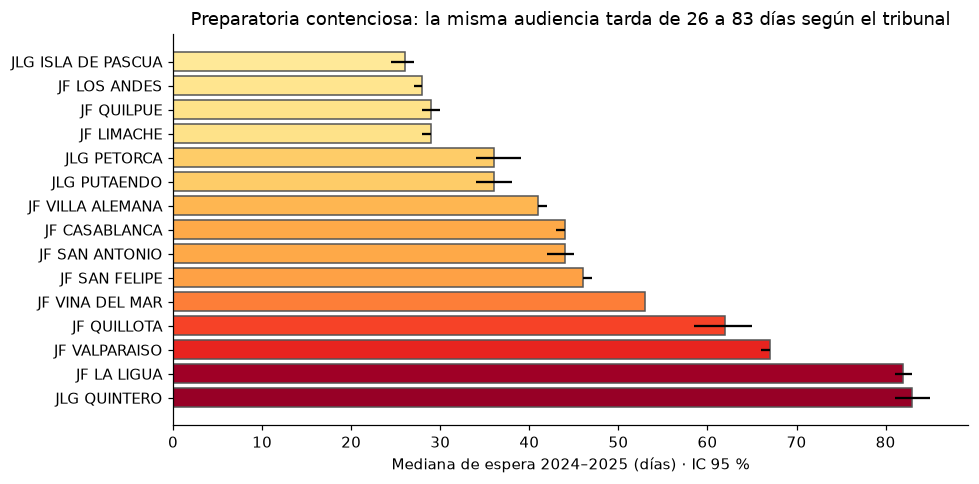

In [14]:
fig, ax = plt.subplots(figsize=(9, 4.5))
cmap = plt.get_cmap("YlOrRd")
norm = (ej["mediana"] - ej["mediana"].min()) / (ej["mediana"].max() - ej["mediana"].min())
ax.barh(ej_vista["TRIBUNAL"], ej["mediana"], color=cmap(0.15 + 0.8 * norm.values),
        xerr=[ej["mediana"] - ej["mediana_ic_inf"], ej["mediana_ic_sup"] - ej["mediana"]], edgecolor="#555")
ax.invert_yaxis(); ax.set_xlabel("Mediana de espera 2024–2025 (días) · IC 95 %")
ax.set_title("Preparatoria contenciosa: la misma audiencia tarda de 26 a 83 días según el tribunal")
plt.tight_layout(); plt.show()

## 11. Exportar artefactos para la app

In [15]:
R = {"clases": me.CLASES, "variables": me.VARS, "excluidas": me.EXCLUIDAS,
     "anio_validacion": me.ANIO_VAL, "anios_prueba": list(me.ANIOS_TEST),
     "recetas": dict(me.ETIQUETA_RECETA),
     "esquemas": {f"{r}|{c}": me.esquema(r, c) for r in me.RECETAS for c in (False, True)},
     "prevalencia": prev.to_dict("records"),
     "tramo": {"tabla": filas_tramo, "eleccion": el_tramo, "curvas": curvas_tramo, "final": info_t},
     "severa": {"tabla": filas_sev, "eleccion": el_sev, "curvas": curvas_sev, "final": info_s},
     "ablacion": ab.to_dict("records")}
me.guardar_artefactos(RAIZ / "models", R, grilla, {"modelo_tramo": m_tramo, "modelo_severa": m_sev})
print(sorted(p.name for p in (RAIZ / "models").iterdir()))

['modelo_severa.joblib', 'modelo_tramo.joblib', 'predicciones_tribunales.parquet', 'resultados_modelado.json']


## 12. Conclusiones

1. **Las probabilidades sirven:** todos los modelos superan con claridad a no usar información (log-loss ~0,87 vs ~1,07).
2. **Un modelo simple basta:** con las 3 variables disponibles al agendar, Gradient Boosting rinde casi igual que el
   bayesiano jerárquico. Se elige el bayesiano por parsimonia y porque se puede explicar.
3. **Los datos recientes pesan más que el algoritmo:** la ventana reciente es la que más mejora. Calibrar solo ayuda cuando se
   entrena con datos antiguos.
4. **Más variables no ayudan** (modalidad, calendario, congestión).
5. **La alerta > 60 días** concentra los casos severos muy por sobre el azar (ver PR-AUC).
6. **La brecha entre tribunales es el hallazgo más accionable:** para la misma audiencia, la espera puede triplicarse.

**Limitaciones:** solo audiencias realizadas (sin suspensiones); no se observan juez, defensa ni contenido de la causa;
una jurisdicción y una materia; los tribunales cambian de un año a otro, así que el modelo debe reentrenarse; comparar
tribunales muestra asociación, no causa.

**Uso responsable:** el comparador es para elegir entre opciones legales, mostrando siempre el N y la incertidumbre.